# Single Spotting Visualization ROI

Output 3 plot:
1. `raw.png`
2. `smooth.png`
3. `combine.png`

ROI dihitung dari 3 area:
- mata + alis kanan
- mata + alis kiri
- mulut

Default pakai orang lain (`SAMPLE_INDEX = 1`).


In [21]:
import re
import sys
from dataclasses import dataclass
from pathlib import Path

import cv2
import dlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from apex import ApexPhase, ApexSmoother
from features_extraction.poc import POC
from features_extraction.quadran import Quadran
from features_extraction.vektor import Vektor
from spotting import SpottingConfig


In [22]:
config = SpottingConfig(
    dataset_root=PROJECT_ROOT / 'dataset' / 'datatest-fix',
    output_root=PROJECT_ROOT / 'output' / 'apex_single_visualization_roi' / 'datatest-fix',
    predictor_path=Path('./models/shape_predictor_68_face_landmarks.dat'),
    video_extensions={'.webm'},
    overwrite=True,
    regions={
        'mata_alis_kanan': list(range(42, 48)) + list(range(22, 27)),
        'mata_alis_kiri': list(range(36, 42)) + list(range(17, 22)),
        'mulut': list(range(48, 68)),
    },
    target_size={
        'mata_alis_kanan': (64, 40),
        'mata_alis_kiri': (64, 40),
        'mulut': (70, 35),
    },
)

# None = auto pilih SAMPLE_INDEX. Isi path kalau mau video tertentu.
VIDEO_PATH = None

# 0 = orang pertama, 1 = orang lain berikutnya.
SAMPLE_INDEX = 10

print(f'DATASET_ROOT = {config.dataset_root}')
print(f'OUTPUT_ROOT = {config.output_root}')
print(f'PREDICTOR = {config.predictor_path}')
print(f'ROI = {list(config.regions)}')


DATASET_ROOT = /home/ryuko/skripsi/Skripsi/Convat-1st/dataset/datatest-fix
OUTPUT_ROOT = /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex_single_visualization_roi/datatest-fix
PREDICTOR = models/shape_predictor_68_face_landmarks.dat
ROI = ['mata_alis_kanan', 'mata_alis_kiri', 'mulut']


In [23]:
@dataclass(slots=True)
class VideoSample:
    video_path: Path
    relative_parent: Path
    stem: str

    @property
    def relative_video_key(self) -> Path:
        return self.relative_parent / self.stem


def natural_sort_key(value: str):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', value)]


def ensure_dir(path: Path) -> None:
    path.mkdir(parents=True, exist_ok=True)


def discover_video_samples(dataset_root: Path, video_extensions: set[str]) -> list[VideoSample]:
    samples = []
    for video_path in sorted(dataset_root.rglob('*'), key=lambda p: natural_sort_key(str(p))):
        if not video_path.is_file():
            continue
        if video_path.suffix.lower() not in video_extensions:
            continue
        rel = video_path.relative_to(dataset_root)
        samples.append(VideoSample(video_path=video_path, relative_parent=rel.parent, stem=video_path.stem))
    return samples


def extract_region(image: np.ndarray, landmarks, indices: list[int]) -> np.ndarray:
    pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in indices]
    xs, ys = zip(*pts)
    left = max(0, min(xs) - config.padding_x)
    top = max(0, min(ys) - config.padding_y)
    right = min(image.shape[1], max(xs) + config.padding_x)
    bottom = min(image.shape[0], max(ys) + config.padding_y)
    return image[top:bottom, left:right]


def detect_landmarks(gray: np.ndarray, detector, predictor):
    faces = detector(gray)
    if len(faces) > 0:
        return predictor(gray, faces[0])
    return None


def compute_frame_magnitudes(prev_gray, prev_lm, curr_gray, curr_lm) -> dict[str, float]:
    roi_values = {}
    for region_name, lm_indices in config.regions.items():
        try:
            roi_prev = extract_region(prev_gray, prev_lm, lm_indices)
            roi_curr = extract_region(curr_gray, curr_lm, lm_indices)
            if roi_prev.size == 0 or roi_curr.size == 0:
                roi_values[region_name] = 0.0
                continue
            target = config.target_size[region_name]
            roi_prev = cv2.resize(roi_prev, target)
            roi_curr = cv2.resize(roi_curr, target)
            poc = POC(roi_prev, roi_curr, config.block_size)
            vec = Vektor(poc.getPOC(), config.block_size)
            quad_data = Quadran(vec.getVektor()).getQuadran()
            magnitudes = [float(block[4]) for block in quad_data]
            roi_values[region_name] = float(np.mean(magnitudes)) if magnitudes else 0.0
        except Exception:
            roi_values[region_name] = 0.0
    return roi_values


def load_video_frames(video_path: Path) -> list[np.ndarray]:
    frames = []
    cap = cv2.VideoCapture(str(video_path))
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)
    cap.release()
    return frames


def build_magnitude_signal(frames: list[np.ndarray], detector, predictor) -> tuple[list[float], pd.DataFrame]:
    if len(frames) < 3:
        return [], pd.DataFrame()
    grays = [cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) for frame in frames]
    magnitudes = []
    roi_rows = []
    prev_gray = grays[0]
    prev_lm = detect_landmarks(prev_gray, detector, predictor)
    for signal_index, curr_gray in enumerate(grays[1:]):
        curr_lm = detect_landmarks(curr_gray, detector, predictor)
        if prev_lm is not None and curr_lm is not None:
            roi_values = compute_frame_magnitudes(prev_gray, prev_lm, curr_gray, curr_lm)
        else:
            roi_values = {region_name: 0.0 for region_name in config.regions}
        mag = float(np.mean(list(roi_values.values()))) if roi_values else 0.0
        magnitudes.append(mag)
        roi_rows.append({
            'signal_index': signal_index,
            'frame_index': signal_index + 1,
            **roi_values,
            'raw_magnitude': mag,
        })
        prev_gray = curr_gray
        prev_lm = curr_lm
    return magnitudes, pd.DataFrame(roi_rows)


In [24]:
if not config.dataset_root.exists():
    raise FileNotFoundError(f'Dataset root not found: {config.dataset_root}')
if not config.predictor_path.exists():
    raise FileNotFoundError(f'Predictor not found: {config.predictor_path}')

samples = discover_video_samples(config.dataset_root, config.video_extensions)
if not samples:
    raise FileNotFoundError(f'No videos found in {config.dataset_root}')

if VIDEO_PATH is None:
    if SAMPLE_INDEX >= len(samples):
        raise IndexError(f'SAMPLE_INDEX={SAMPLE_INDEX}, samples={len(samples)}')
    sample = samples[SAMPLE_INDEX]
else:
    video_path = Path(VIDEO_PATH)
    if not video_path.is_absolute():
        video_path = (PROJECT_ROOT / video_path).resolve()
    rel = video_path.relative_to(config.dataset_root)
    sample = VideoSample(video_path=video_path, relative_parent=rel.parent, stem=video_path.stem)

print(f'SAMPLE_INDEX = {SAMPLE_INDEX if VIDEO_PATH is None else "custom"}')
print(f'SAMPLE = {sample.relative_video_key}')
print(sample.video_path)


SAMPLE_INDEX = 10
SAMPLE = anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main
/home/ryuko/skripsi/Skripsi/Convat-1st/dataset/datatest-fix/anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main.webm


In [25]:
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(str(config.predictor_path))

frames = load_video_frames(sample.video_path)
if len(frames) < 3:
    raise ValueError(f'Too few frames: {len(frames)}')

raw_signal, roi_df = build_magnitude_signal(frames, detector, predictor)
if len(raw_signal) < 5:
    raise ValueError(f'Too few magnitudes: {len(raw_signal)}')

smooth_signal = ApexSmoother.smooth(raw_signal)

phase_detector = ApexPhase(
    distance_threshold=config.distance_threshold,
    prominence_threshold=config.prominence_threshold,
    cutoff_ratio=config.cutoff_ratio,
)


def detect_phases(signal: list[float]) -> tuple[list[int], dict, float]:
    signal_arr = np.asarray(signal, dtype=float)
    threshold = float(signal_arr.mean() + signal_arr.std())
    apex_indices = phase_detector.find_top_k_apex(signal, k=config.top_k_apex, height=threshold)
    phases = phase_detector.find_phase(signal, apex_indices) if apex_indices else {}
    valid_apex = []
    valid_phases = {}
    for apex_idx in apex_indices:
        phase = phases[apex_idx]
        duration = int(phase['end'] - phase['start'])
        if duration < config.min_phase_duration:
            continue
        valid_apex.append(int(apex_idx))
        valid_phases[int(apex_idx)] = {'start': int(phase['start']), 'end': int(phase['end'])}
    return valid_apex, valid_phases, threshold


raw_apex, raw_phases, raw_threshold = detect_phases(raw_signal)
smooth_apex, smooth_phases, smooth_threshold = detect_phases(smooth_signal)

signal_df = roi_df.copy()
signal_df['smoothed_magnitude'] = smooth_signal

print(f'frames={len(frames)} raw={len(raw_signal)} smooth={len(smooth_signal)}')
print(f'raw_apex={raw_apex}')
print(f'smooth_apex={smooth_apex}')
print(f'ROI columns={list(config.regions)}')
signal_df.head()


frames=237 raw=236 smooth=236
raw_apex=[39, 67, 104, 171, 194]
smooth_apex=[41, 69, 104, 173]
ROI columns=['mata_alis_kanan', 'mata_alis_kiri', 'mulut']


,signal_index,frame_index,mata_alis_kanan,mata_alis_kiri,mulut,raw_magnitude,smoothed_magnitude
0,0,1,0.022222,0.000000,0.00,0.007407,0.002421
1,1,2,0.000000,0.000000,0.00,0.000000,0.012225
2,2,3,0.022222,0.022222,0.00,0.014815,0.021677
3,3,4,0.111111,0.022222,0.04,0.057778,0.030652
4,4,5,0.111111,0.000000,0.04,0.050370,0.039025


In [26]:
output_dir = config.output_root / sample.relative_video_key
ensure_dir(output_dir)

raw_path = output_dir / 'raw.png'
smooth_path = output_dir / 'smooth.png'
combine_path = output_dir / 'combine.png'
excel_path = output_dir / 'signal.xlsx'

signal_df.to_excel(excel_path, index=False)
print(f'Saved signal data: {excel_path}')


Saved signal data: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex_single_visualization_roi/datatest-fix/anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main/signal.xlsx


In [27]:
def plot_signal_style(
    signal: list[float],
    apex_indices: list[int],
    phases: dict,
    threshold: float,
    title: str,
    save_path: Path,
    *,
    line_label: str = 'Signal',
    line_color: str = 'blue',
) -> None:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(signal, label=line_label, color=line_color)
    ax.axhline(
        threshold,
        color='gray',
        linestyle='--',
        alpha=0.5,
        label=f'Mean+1σ ({threshold:.4f})',
    )
    for i, apex_idx in enumerate(apex_indices):
        ax.plot(apex_idx, signal[apex_idx], 'ro', label='Apex' if i == 0 else '')
        phase = phases.get(apex_idx)
        if phase is None:
            continue
        ax.axvspan(
            phase['start'],
            phase['end'],
            color='orange',
            alpha=0.3,
            label='Apex Phase' if i == 0 else '',
        )
    ax.set_title(title)
    ax.set_xlabel('Frame Index')
    ax.set_ylabel('Signal Value')
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.savefig(save_path, bbox_inches='tight', dpi=300)
    plt.show()
    plt.close(fig)


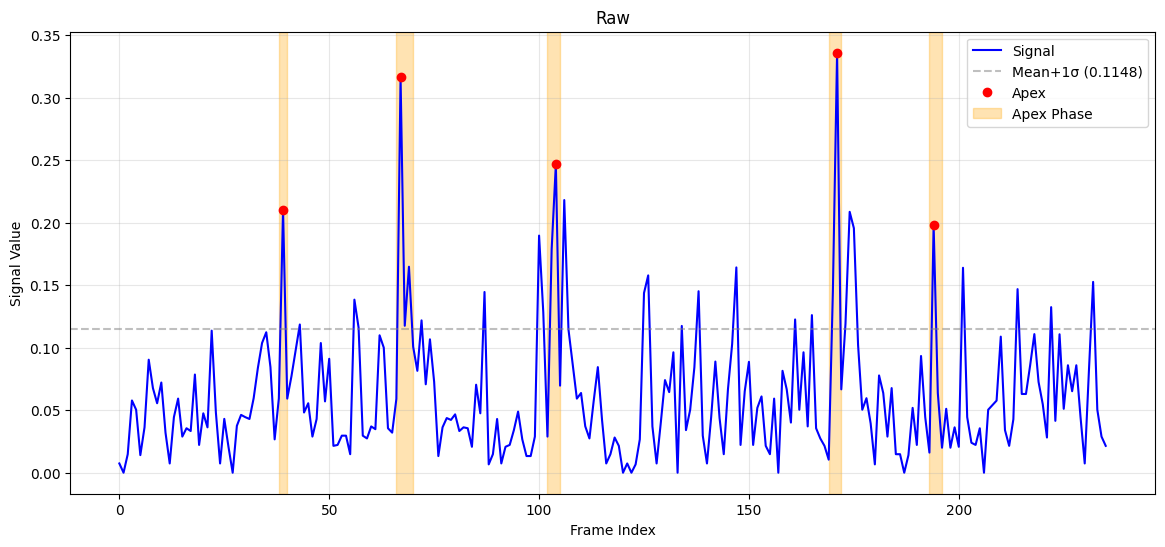

Saved raw plot: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex_single_visualization_roi/datatest-fix/anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main/raw.png


In [28]:
plot_signal_style(
    raw_signal,
    raw_apex,
    raw_phases,
    raw_threshold,
    f'Raw',
    raw_path,
)
print(f'Saved raw plot: {raw_path}')


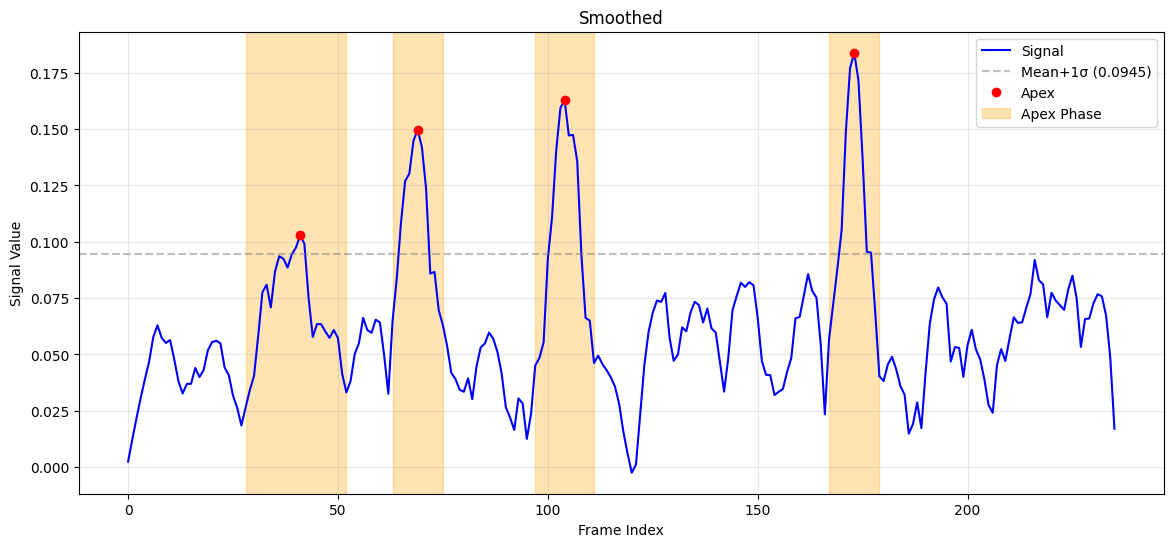

Saved smooth plot: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex_single_visualization_roi/datatest-fix/anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main/smooth.png


In [29]:
plot_signal_style(
    smooth_signal,
    smooth_apex,
    smooth_phases,
    smooth_threshold,
    f'Smoothed',
    smooth_path,
)
print(f'Saved smooth plot: {smooth_path}')


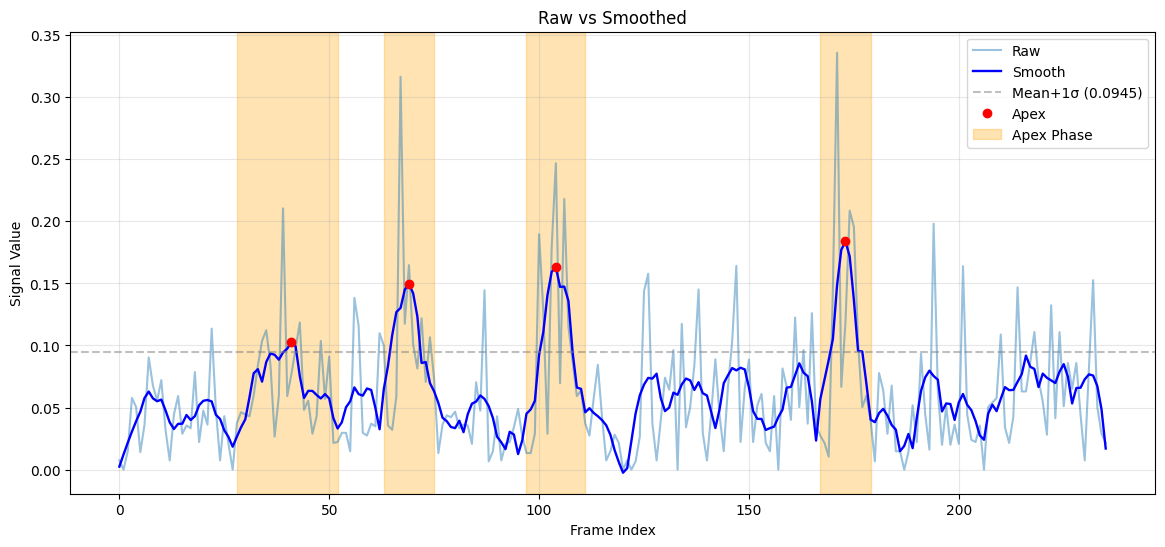

Saved combine plot: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex_single_visualization_roi/datatest-fix/anxiety-rendah/ilham_dharma_atmaja_1776395335293/q1/Ilham Dharma Atmaja_1_15d591ce-051a-47f2-ac38-367c1e6189c7_main/combine.png


In [30]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(raw_signal, label='Raw', color='tab:blue', alpha=0.45)
ax.plot(smooth_signal, label='Smooth', color='blue', linewidth=1.7)
ax.axhline(
    smooth_threshold,
    color='gray',
    linestyle='--',
    alpha=0.5,
    label=f'Mean+1σ ({smooth_threshold:.4f})',
)
for i, apex_idx in enumerate(smooth_apex):
    ax.plot(apex_idx, smooth_signal[apex_idx], 'ro', label='Apex' if i == 0 else '')
    phase = smooth_phases.get(apex_idx)
    if phase is None:
        continue
    ax.axvspan(
        phase['start'],
        phase['end'],
        color='orange',
        alpha=0.3,
        label='Apex Phase' if i == 0 else '',
    )
ax.set_title(f'Raw vs Smoothed')
ax.set_xlabel('Frame Index')
ax.set_ylabel('Signal Value')
ax.legend()
ax.grid(True, alpha=0.3)
fig.savefig(combine_path, bbox_inches='tight', dpi=300)
plt.show()
plt.close(fig)

print(f'Saved combine plot: {combine_path}')


## Output

Cek folder printed di atas:
- `raw.png`
- `smooth.png`
- `combine.png`
- `signal.xlsx`
